# 📘 Notebook 12: Diffusion Models, Creating Images by Removing Noise

### Course: *From Papers to Practice: Landmark Deep Learning Architectures*
**Instructor:** Ioannis Tsioulis

*Papers: Sohl-Dickstein et al. (2015) · Ho, Jain and Abbeel (2020)*

---

> 💡 **This notebook is already run.** Every number and picture below was produced by the code above it, and each result is followed by a comment that explains what it shows. You can read it without running anything, or choose **Runtime → Run all** in Colab.
>
> ⏱️ **Training time and limitations.** A small U-Net (Notebook 10) learns to remove noise from MNIST digits reduced to 16 × 16 pixels, for 2,500 steps: about **15 minutes** on a laptop processor, a few minutes on a Colab GPU. The DDPM paper used 1,000 noise steps, a U-Net of 35 million weights with attention layers and 800,000 training steps on 32 × 32 colour images (CIFAR-10), on TPUs. Our digits will be recognisable but rough; the **mechanism** (forward noising, a noise-predicting network, step-by-step sampling) is exactly that of the paper. Stable Diffusion and similar systems add a VAE to work in a compressed space (Notebook 08) and a text encoder to steer the image, which we do not cover.

## 🎯 Learning objectives

By the end of this notebook you will be able to:

- Explain the **forward process**: destroying an image by adding a little Gaussian noise at each of $T$ steps
- Use the closed formula that jumps straight to **any** noise level
- Explain the training objective of DDPM: a network that **predicts the noise** that was added
- Implement the **reverse process** that generates an image from pure noise, step by step
- Compare diffusion with VAEs and GANs

> **Prerequisites:** [Notebook 10: U-Net](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/10_unet.ipynb), and Notebooks [08](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/08_autoencoder_vae.ipynb) and [09](https://colab.research.google.com/github/giannis00/giannis00.github.io/blob/main/assets/jupyter/from-papers-to-practice/09_gan.ipynb) for the other generative models.
>
> 🔭 **Why this notebook matters:** DALL·E 2, Imagen, Midjourney and Stable Diffusion all generate images by diffusion, and the same idea now produces video, audio and even protein structures. The 2020 DDPM paper turned an elegant but impractical 2015 idea into a method that beat GANs on image quality while training stably.

## 1. The papers

> 📄 J. Sohl-Dickstein, E. Weiss, N. Maheswaranathan and S. Ganguli, [*Deep Unsupervised Learning using Nonequilibrium Thermodynamics*](https://arxiv.org/abs/1503.03585), ICML 2015.
>
> 📄 J. Ho, A. Jain and P. Abbeel, [*Denoising Diffusion Probabilistic Models*](https://arxiv.org/abs/2006.11239), NeurIPS 2020.

### Intuition first
Destroying an image is easy: add a little random noise, then a little more, and after enough steps nothing is left but static. **Diffusion models learn to run this film backwards.**

- **Forward process (fixed, no learning):** over $T$ steps, mix the image with a small amount of Gaussian noise each time, until it is pure noise.
- **Reverse process (learned):** train a network that, given a noisy image and the step number, predicts the noise in it. Subtracting a bit of that predicted noise gives a slightly cleaner image. Repeat from step $T$ down to step 1, starting from pure static, and an image appears.

Each single step is easy: removing a *little* noise from an *almost* clean image. The difficulty of creating an image from nothing is split into hundreds of easy steps, which is why training is stable (no adversary, as in GANs) and the results sharp (no blurry average, as in VAEs).

### Formal definition
With a noise schedule $\beta_1, \dots, \beta_T$ and $\bar\alpha_t = \prod_{s \le t} (1 - \beta_s)$, the noisy image at step $t$ can be produced **directly** from the clean image $x_0$:

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1 - \bar\alpha_t}\, \epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)$$

DDPM's training objective is remarkably simple: pick a random image, a random step $t$ and random noise $\epsilon$, build $x_t$, and train the network $\epsilon_\theta(x_t, t)$ to predict $\epsilon$ with a mean squared error.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import gzip
import math
import time
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 80

MIRROR = "https://ossci-datasets.s3.amazonaws.com/mnist/"
def read_idx(name, header):
    return np.frombuffer(gzip.decompress(urllib.request.urlopen(MIRROR + name).read()), dtype=np.uint8, offset=header)
X = torch.tensor(read_idx("train-images-idx3-ubyte.gz", 16).reshape(-1, 1, 28, 28), dtype=torch.float32) / 255
X = F.interpolate(F.pad(X, (2, 2, 2, 2)), size=16, mode="bilinear", align_corners=False) * 2 - 1   # 16 x 16, values in [-1, 1]
print("training images:", tuple(X.shape))

training images: (60000, 1, 16, 16)


## 2. The forward process: destroying digits

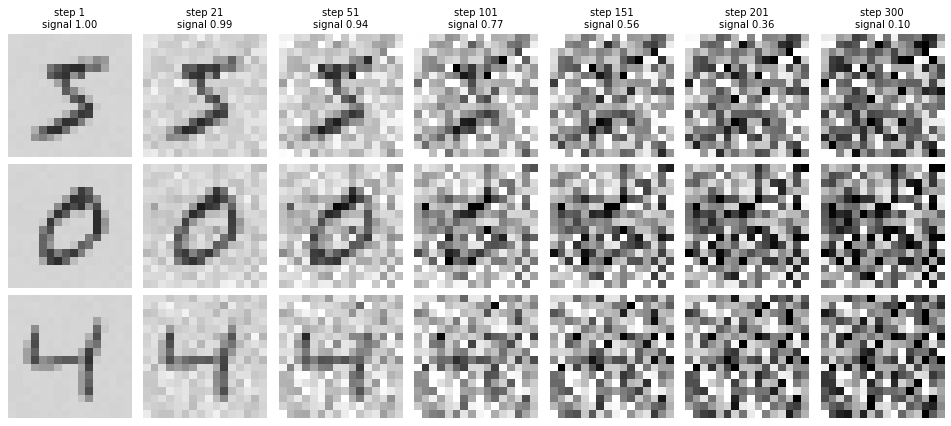

In [2]:
T = 300
betas = torch.linspace(1e-4, 0.03, T)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, 0)

def add_noise(x0, t, noise):
    a = alpha_bar[t].view(-1, 1, 1, 1)
    return a.sqrt() * x0 + (1 - a).sqrt() * noise

steps_to_show = [0, 20, 50, 100, 150, 200, 299]
fig, axes = plt.subplots(3, len(steps_to_show), figsize=(12, 5.4))
torch.manual_seed(0)
for r in range(3):
    noise = torch.randn(1, 1, 16, 16)
    for c, t in enumerate(steps_to_show):
        axes[r, c].imshow(add_noise(X[r:r + 1], torch.tensor([t]), noise)[0, 0], cmap="gray_r", vmin=-1.5, vmax=1.5)
        axes[r, c].axis("off")
        if r == 0:
            axes[r, c].set_title(f"step {t + 1}\nsignal {alpha_bar[t].sqrt():.2f}", fontsize=9)
plt.tight_layout()
plt.show()

**What we see.** Three digits (a 5, a 0 and a 4) destroyed step by step with the same formula. The "signal" above each column is $\sqrt{arlpha_t}$, the share of the original image left. After 20 steps the digits are barely touched (99%); by step 101 only 77% of the signal remains and the strokes are hard to see; at step 300 only **10%** is left and the images look like pure static. Note that the formula jumps **directly** to any step: we never have to run the 300 small steps one after another during training.

## 3. The denoising network

A small U-Net (Notebook 10) takes the noisy image and the step number. The step is turned into a vector with the same sine and cosine encoding the Transformer uses for positions (Notebook 07), and added to the feature maps, so that the network knows how much noise to expect.

In [3]:
def step_embedding(t, d):
    freq = torch.exp(-math.log(10000) * torch.arange(0, d, 2) / d)
    angles = t.float()[:, None] * freq[None]
    return torch.cat([angles.sin(), angles.cos()], 1)

class Block(nn.Module):
    def __init__(self, cin, cout, d_t=64):
        super().__init__()
        self.conv1, self.conv2 = nn.Conv2d(cin, cout, 3, padding=1), nn.Conv2d(cout, cout, 3, padding=1)
        self.norm1, self.norm2 = nn.GroupNorm(8, cout), nn.GroupNorm(8, cout)
        self.time = nn.Linear(d_t, cout)
    def forward(self, x, t_emb):
        h = F.silu(self.norm1(self.conv1(x)))
        h = h + self.time(t_emb)[:, :, None, None]       # tell the block which step we are at
        return F.silu(self.norm2(self.conv2(h)))

class Denoiser(nn.Module):
    def __init__(self, c=16):
        super().__init__()
        self.t_mlp = nn.Sequential(nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 64))
        self.down1, self.down2 = Block(1, c), Block(c, 2 * c)
        self.mid = Block(2 * c, 2 * c)
        self.up2 = Block(4 * c, c)
        self.up1 = Block(2 * c, c)
        self.out = nn.Conv2d(c, 1, 1)
    def forward(self, x, t):
        e = self.t_mlp(step_embedding(t, 64))
        d1 = self.down1(x, e)                               # 16 x 16
        d2 = self.down2(F.avg_pool2d(d1, 2), e)             # 8 x 8
        m = self.mid(F.avg_pool2d(d2, 2), e)                # 4 x 4
        u2 = self.up2(torch.cat([F.interpolate(m, scale_factor=2), d2], 1), e)
        u1 = self.up1(torch.cat([F.interpolate(u2, scale_factor=2), d1], 1), e)
        return self.out(u1)                                 # the predicted noise

net = Denoiser()
print("weights:", f"{sum(p.numel() for p in net.parameters()):,}")

weights: 69,425


**What we see.** The denoiser has **69,425** weights, a small U-Net with skip connections (Notebook 10) and the step embedding added inside each block. It is tiny by diffusion standards: Stable Diffusion's U-Net has about 860 million.

## 4. Training: predict the noise

trained in 1043 s; loss over the first 100 steps 0.182, last 100 steps 0.055


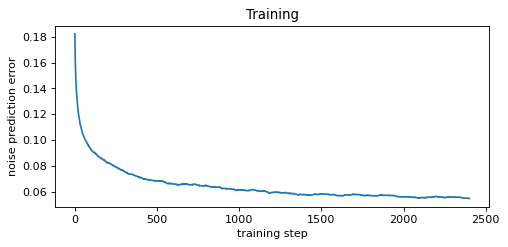

In [4]:
STEPS = 2500
opt = torch.optim.Adam(net.parameters(), lr=2e-3)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, STEPS)
losses, start = [], time.time()
torch.manual_seed(0)
for step in range(STEPS):
    x0 = X[torch.randint(0, len(X), (128,))]
    t = torch.randint(0, T, (128,))
    noise = torch.randn_like(x0)
    loss = F.mse_loss(net(add_noise(x0, t, noise), t), noise)
    opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    losses.append(loss.item())
print(f"trained in {time.time() - start:.0f} s; loss over the first 100 steps {np.mean(losses[:100]):.3f}, last 100 steps {np.mean(losses[-100:]):.3f}")
plt.figure(figsize=(7, 3))
plt.plot(np.convolve(losses, np.ones(100) / 100, mode="valid"))
plt.xlabel("training step"); plt.ylabel("noise prediction error"); plt.title("Training")
plt.show()

**What we see.** The noise-prediction error falls from about **0.18** to **0.055**. The curve flattens early, yet the samples keep improving with longer training; for diffusion models the loss is a poor guide to image quality. Training took about 15 to 20 minutes on this processor.

## 5. Generating digits from pure noise

The reverse process of DDPM: start from pure noise $x_T$ and, for $t = T, \dots, 1$, remove the predicted noise and add back a little fresh noise:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1 - \bar\alpha_t}}\, \epsilon_\theta(x_t, t)\right) + \sqrt{\beta_t}\, z$$

sampled 8 images in 7.2 s (300 network calls each)


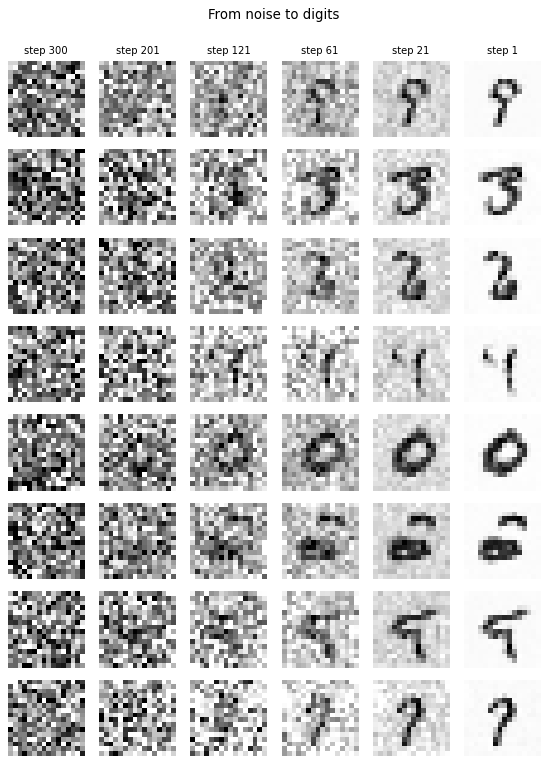

In [5]:
@torch.no_grad()
def sample(n, keep=(299, 200, 120, 60, 20, 0), seed=0):
    torch.manual_seed(seed)
    net.eval()
    x = torch.randn(n, 1, 16, 16)
    snapshots = {}
    for t in range(T - 1, -1, -1):
        tt = torch.full((n,), t)
        eps = net(x, tt)
        x = (x - betas[t] / (1 - alpha_bar[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 0:
            x = x + betas[t].sqrt() * torch.randn_like(x)
        if t in keep:
            snapshots[t] = x.clone()
    return x.clamp(-1, 1), snapshots

start = time.time()
final, snaps = sample(8)
print(f"sampled 8 images in {time.time() - start:.1f} s ({T} network calls each)")
fig, axes = plt.subplots(8, len(snaps), figsize=(7, 9.5))
for c, t in enumerate(sorted(snaps, reverse=True)):
    for r in range(8):
        axes[r, c].imshow(snaps[t][r, 0].clamp(-1.5, 1.5), cmap="gray_r"); axes[r, c].axis("off")
    axes[0, c].set_title(f"step {t + 1}", fontsize=9)
plt.suptitle("From noise to digits", y=1.0)
plt.tight_layout()
plt.show()

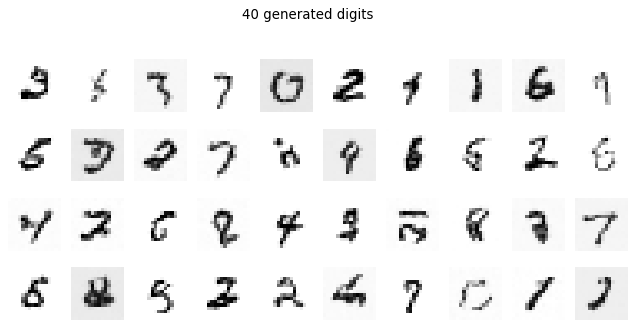

In [6]:
final, _ = sample(40, seed=1)
fig, axes = plt.subplots(4, 10, figsize=(10, 4.4))
for ax, img in zip(axes.ravel(), final):
    ax.imshow(img[0], cmap="gray_r", vmin=-1, vmax=1); ax.axis("off")
plt.suptitle("40 generated digits", y=1.02)
plt.show()

**What we see.** The middle figure is the reverse film. Each row starts from **pure static** (step 300) and the same network is applied 300 times. At step 121 faint shapes appear, by step 61 a digit is recognisable, and the last steps only clean up the background. Different random starting noise gives different digits: a 9, a 3, a 2, a 0, a 7.

The 40 samples in the last figure show what a model of 69 thousand weights, trained for a few minutes, can do: most are clear, varied digits (0, 2, 3, 6, 7, 9...), with sharp strokes and no blur. A few are malformed, and some keep a light grey background: traces of noise that a larger network, more training and more steps would remove. Compare with the blurry VAE samples (Notebook 08) and the speckled GAN samples (Notebook 09): even this small diffusion model combines sharpness with variety, which is why diffusion took over image generation.

## ⚠️ Common pitfalls

- **Forgetting the step number.** Without it, the network cannot know whether to remove a whisper of noise or almost everything.
- **Mixing up the schedules.** Training and sampling must use exactly the same $\beta_t$, $\alpha_t$ and $\bar\alpha_t$.
- **Expecting fast sampling.** Generating one image needs one network call per step (300 here, 1,000 in the paper); later methods (DDIM, distillation) cut this to a few dozen or even one.
- **Comparing the training loss to image quality.** The noise prediction error drops quickly and then barely moves, while samples keep improving; look at samples.
- **Pixel range.** The process assumes data around 0 with values in about [-1, 1]; images in [0, 255] would make the noise schedule meaningless.

## ✏️ Exercises

### Exercise 1 (Fewer sampling steps)
Sample by visiting only every 10th step (30 network calls instead of 300), recomputing $\alpha$ and $\beta$ for the bigger jumps. Simplest version: keep the formula but use `alpha_bar[t] / alpha_bar[t_prev]` as the step's $\alpha$. How do the digits look?

In [7]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
@torch.no_grad()
def sample_fast(n, stride=10, seed=0):
    torch.manual_seed(seed)
    x = torch.randn(n, 1, 16, 16)
    ts = list(range(T - 1, -1, -stride))
    for i, t in enumerate(ts):
        t_prev = ts[i + 1] if i + 1 < len(ts) else -1
        ab_prev = alpha_bar[t_prev] if t_prev >= 0 else torch.tensor(1.0)
        a = alpha_bar[t] / ab_prev
        b = 1 - a
        eps = net(x, torch.full((n,), t))
        x = (x - b / (1 - alpha_bar[t]).sqrt() * eps) / a.sqrt()
        if t_prev >= 0:
            x = x + b.sqrt() * 0.5 * torch.randn_like(x)
    return x.clamp(-1, 1)

imgs = sample_fast(10)
fig, axes = plt.subplots(1, 10, figsize=(10, 1.2))
for ax, img in zip(axes, imgs):
    ax.imshow(img[0], cmap="gray_r", vmin=-1, vmax=1); ax.axis("off")
plt.show()
```

*Ten times fewer steps still give digit-like shapes, though usually rougher, because each step now has to remove much more noise than the network was trained for. Faster samplers such as DDIM make big jumps properly and are one reason diffusion became practical.*
</details>

### Exercise 2 (A denoiser on its own)
Take a test-like digit, add noise at step 100, and ask the network to predict the clean image directly in **one** step: $\hat{x}_0 = (x_t - \sqrt{1 - \bar\alpha_t}\,\epsilon_\theta) / \sqrt{\bar\alpha_t}$. Show the noisy image and the estimate.

In [8]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
t = torch.tensor([100])
x0 = X[-1:]
torch.manual_seed(5)
xt = add_noise(x0, t, torch.randn_like(x0))
with torch.no_grad():
    eps = net(xt, t)
x0_hat = (xt - (1 - alpha_bar[t]).sqrt() * eps) / alpha_bar[t].sqrt()
fig, axes = plt.subplots(1, 3, figsize=(6, 2.2))
for ax, img, title in zip(axes, [x0, xt, x0_hat], ["clean", "noisy (step 101)", "one-step estimate"]):
    ax.imshow(img[0, 0].clamp(-1.5, 1.5), cmap="gray_r"); ax.set_title(title, fontsize=9); ax.axis("off")
plt.show()
```

*From a heavily noised digit, one step already recovers a blurry version of it: the network has become a good denoiser. Diffusion sampling is just this denoiser, applied gently many times.*
</details>

### Exercise 3 (How varied are the samples?)
Generate 200 digits and classify them with a quick logistic regression trained on 16 × 16 MNIST (use `sklearn.linear_model.LogisticRegression` on 10,000 flattened images). How evenly are the ten digits represented?

In [9]:
# Your solution here:

<details><summary>💡 Show solution</summary>

```python
from sklearn.linear_model import LogisticRegression
labels = read_idx("train-labels-idx1-ubyte.gz", 8)
clf = LogisticRegression(max_iter=300).fit(X[:10000].reshape(10000, -1).numpy(), labels[:10000])
gen, _ = sample(200, keep=(), seed=2)
pred = clf.predict(gen.reshape(200, -1).numpy())
print("share of each digit:", np.round(np.bincount(pred, minlength=10) / 200, 3))
```

*Diffusion models are known for good **coverage**: the samples spread over all ten digits, without the mode collapse that GANs can suffer (Notebook 09). Some digits may be under- or over-represented in a small sample, and a rough generator also produces a few shapes the classifier assigns arbitrarily.*
</details>

## 🔑 Key takeaways

- A **diffusion model** learns to reverse a fixed process that gradually turns images into noise.
- Training is simple and stable: predict the **noise** added at a random step, with a mean squared error.
- Generation starts from **pure noise** and removes predicted noise step by step; it is slow because each step needs a network call.
- The denoiser is a **U-Net** that also receives the **step number**.
- Diffusion combines the stable training and coverage of VAEs with the sharpness of GANs, and powers today's image, video and audio generators.

---
**This is the last notebook of the course.** From a single perceptron that could not learn XOR to a network that paints digits out of static: every step was one idea, published in one paper, and tested here in a few minutes.

---
*© Ioannis Tsioulis. *From Papers to Practice: Landmark Deep Learning Architectures*. Prepared for educational use.*